# 0. Auditoria da base de legislação trabalhista

## Objetivo

Verificar a composição, a integridade, os metadados e a legibilidade
dos documentos selecionados do repositório LawCodex/br antes da
exploração e da preparação para um sistema RAG.

## Escopo

A auditoria abrange:

- Conferência dos arquivos esperados.
- Inventário e hashes dos arquivos.
- Identificação da versão do repositório.
- Leitura dos metadados YAML.
- Identificação de fontes e datas de coleta declaradas.
- Detecção de duplicações.
- Verificação inicial da qualidade textual.
- Registro de problemas e pendências.

## Limitações

Esta auditoria não comprova:

- A vigência jurídica das normas.
- A completude dos textos em relação às fontes oficiais.
- A atualização das fontes até a data de execução.
- A cobertura completa do Direito do Trabalho.

O campo `status` fornecido pelo repositório será tratado como informação
declarada, e não como comprovação independente de vigência.

Os arquivos originais não serão modificados.

# 1. Auditoria e Diagnóstico de Dados Brutos (Legislação)

Este notebook verifica a seleção de arquivos do repositório LawCodex/br antes da exploração e da preparação para um sistema RAG.

**Objetivos:**
1. Inventário, seleção esperada e separação de arquivos auxiliares.
2. Registro da versão do repositório e hashes dos arquivos.
3. Verificação de leitura, encoding e problemas de extração.
4. Validação dos metadados YAML e detecção de duplicações exatas.
5. Consolidação das pendências e exportação dos resultados.

A contagem de dispositivos, a organização jurídica e a distribuição de tamanhos em tokens serão exploradas no notebook 02_eda_clt.ipynb.

In [1]:
import os
import re
import json
import hashlib
import subprocess
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

# Configuração de estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)

# Procura a pasta de dados no diretório atual e nos seus ancestrais.
CWD = Path.cwd().resolve()
RAW_DIR = next(
    (base / "data/raw/legislacao" for base in (CWD, *CWD.parents)
     if (base / "data/raw/legislacao").is_dir()),
    None,
)

if RAW_DIR is None:
    raise FileNotFoundError(
        f"Pasta data/raw/legislacao não encontrada a partir de {CWD}. "
        "Abra o notebook dentro da pasta do projeto lex_clt.ai."
    )

PROJECT_ROOT = RAW_DIR.parents[2]
REPORT_DIR = PROJECT_ROOT / "reports/legislacao/auditoria"
EXECUTADO_EM = datetime.now(timezone.utc).isoformat()

print(f"✅ Diretório encontrado com sucesso: {RAW_DIR}")

✅ Diretório encontrado com sucesso: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\raw\legislacao


## 1. Inventário, Formatos e Cobertura das Normas
Mapeamento dos arquivos, separando a legislação dos arquivos auxiliares. O caminho relativo identifica cada arquivo nas etapas seguintes.

In [2]:
def audit_inventory(base_path):
    records = []
    for file_path in sorted(base_path.rglob("*.md")):
        rel_path = file_path.relative_to(base_path)
        if ".git" in rel_path.parts or not file_path.is_file():
            continue

        parts = rel_path.parts
        is_auxiliar = file_path.name.lower() == "readme.md" or len(parts) == 1
        records.append({
            "nome_arquivo": file_path.name,
            "categoria": parts[0] if len(parts) > 1 else "auxiliar",
            "tipo_dado": "Auxiliar" if is_auxiliar else "Legislação",
            "caminho_relativo": rel_path.as_posix(),
            "tamanho_bytes": file_path.stat().st_size,
            "tamanho_kb": round(file_path.stat().st_size / 1024, 2),
            "extensao": file_path.suffix
        })

    columns = ["nome_arquivo", "categoria", "tipo_dado", "caminho_relativo",
               "tamanho_bytes", "tamanho_kb", "extensao"]
    return pd.DataFrame(records, columns=columns)

df_inv = audit_inventory(RAW_DIR)
df_legislacao = df_inv[df_inv["tipo_dado"] == "Legislação"].reset_index(drop=True)
df_auxiliares = df_inv[df_inv["tipo_dado"] == "Auxiliar"].reset_index(drop=True)

if df_legislacao.empty:
    raise ValueError("Nenhum arquivo de legislação encontrado. Verifique a seleção dos dados.")

print(f"• Total de arquivos de Legislação: {len(df_legislacao)}")
print(f"• Total de arquivos Auxiliares: {len(df_auxiliares)}")
display(df_legislacao.head())

• Total de arquivos de Legislação: 25
• Total de arquivos Auxiliares: 1


,nome_arquivo,categoria,tipo_dado,caminho_relativo,tamanho_bytes,tamanho_kb,extensao
0,codigo-civil-lei-10406-2002.md,codigos,Legislação,codigos/codigo-civil-lei-10406-2002.md,673262,657.48,.md
1,codigo-de-processo-civil-lei-13105-2015.md,codigos,Legislação,codigos/codigo-de-processo-civil-lei-13105-201...,613050,598.68,.md
2,consolidacao-das-leis-do-trabalho-clt-del-5452...,codigos,Legislação,codigos/consolidacao-das-leis-do-trabalho-clt-...,656448,641.06,.md
3,constituicao-1988.md,constituicao,Legislação,constituicao/constituicao-1988.md,717043,700.24,.md
4,lei-605-1949.md,leis,Legislação,leis/1949/lei-605-1949.md,9065,8.85,.md


### Conferência da seleção esperada
A lista abaixo registra a seleção inicial do projeto, não a cobertura completa do Direito do Trabalho. Atualize-a explicitamente quando o escopo mudar.

In [3]:
ARQUIVOS_ESPERADOS = [
    "codigos/codigo-civil-lei-10406-2002.md",
    "codigos/codigo-de-processo-civil-lei-13105-2015.md",
    "codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md",
    "constituicao/constituicao-1988.md",
    "leis-complementares/2015/lcp-150-2015.md",
    "leis/1949/lei-605-1949.md",
    "leis/1962/lei-4090-1962.md",
    "leis/1965/lei-4749-1965.md",
    "leis/1970/lei-5584-1970.md",
    "leis/1973/lei-5889-1973.md",
    "leis/1974/lei-6019-1974.md",
    "leis/1985/lei-7418-1985.md",
    "leis/1989/lei-7783-1989.md",
    "leis/1990/lei-7998-1990.md",
    "leis/1990/lei-8036-1990.md",
    "leis/1991/lei-8212-1991.md",
    "leis/1991/lei-8213-1991.md",
    "leis/1995/lei-9029-1995.md",
    "leis/2000/lei-10101-2000.md",
    "leis/2006/lei-11419-2006.md",
    "leis/2008/lei-11788-2008.md",
    "leis/2011/lei-12506-2011.md",
    "leis/2022/lei-14442-2022.md",
    "leis/2022/lei-14457-2022.md",
    "leis/2023/lei-14611-2023.md"
]

encontrados = set(df_legislacao["caminho_relativo"])
esperados = set(ARQUIVOS_ESPERADOS)
df_cobertura = pd.DataFrame([
    {"caminho_relativo": caminho,
     "status_selecao": "Ausente" if caminho not in encontrados else
                       "Não previsto" if caminho not in esperados else "OK"}
    for caminho in sorted(esperados | encontrados)
])

print(f"• Arquivos esperados ausentes: {(df_cobertura['status_selecao'] == 'Ausente').sum()}")
print(f"• Arquivos não previstos: {(df_cobertura['status_selecao'] == 'Não previsto').sum()}")
display(df_cobertura[df_cobertura["status_selecao"] != "OK"])

• Arquivos esperados ausentes: 0
• Arquivos não previstos: 0


,caminho_relativo,status_selecao


### Gráfico 1: Distribuição do Tamanho por Norma

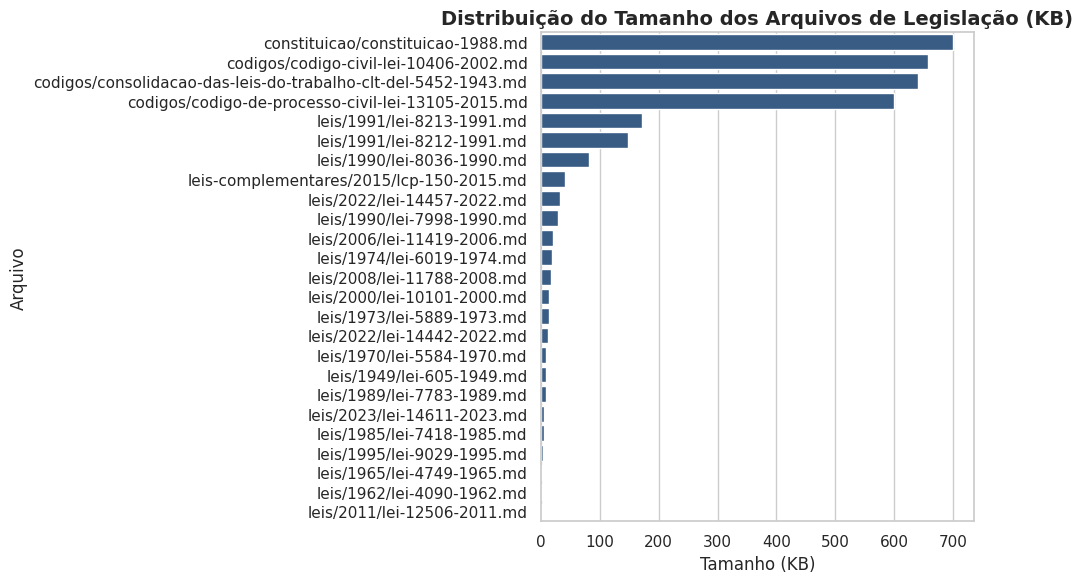

In [4]:
plt.figure(figsize=(10, 6))
df_sorted = df_legislacao.sort_values(by="tamanho_kb", ascending=False)
sns.barplot(data=df_sorted, x="tamanho_kb", y="caminho_relativo", color="#2b5c8f")
plt.title("Distribuição do Tamanho dos Arquivos de Legislação (KB)", fontsize=14, fontweight='bold')
plt.xlabel("Tamanho (KB)", fontsize=12)
plt.ylabel("Arquivo", fontsize=12)
plt.tight_layout()
plt.show()

## 2. Rastreabilidade da Fonte
Registramos o commit efetivamente consultado, a comparação com o README dos dados e o estado local. Falhas de inspeção são alertas e não são interpretadas como repositório sem alterações. Os comandos Git não devem buscar objetos na rede.

In [5]:
def inspect_repository(base_path):
    result = {"commit": None, "commit_declarado": None, "commit_confere": None,
              "alteracoes_locais": None, "erros_git": []}
    readme_path = PROJECT_ROOT / "data/README.md"
    if readme_path.is_file():
        match = re.search(r"Commit utilizado:\s*([0-9a-fA-F]{40})", readme_path.read_text(encoding="utf-8"))
        if match:
            result["commit_declarado"] = match.group(1).lower()

    env = os.environ.copy()
    env["GIT_NO_LAZY_FETCH"] = "1"
    env["GIT_TERMINAL_PROMPT"] = "0"
    for key, args in [("commit", ["rev-parse", "HEAD"]),
                      ("alteracoes_locais", ["status", "--porcelain", "--untracked-files=normal"])]:
        try:
            command = subprocess.run(
                ["git", "-C", str(base_path), *args], capture_output=True,
                text=True, encoding="utf-8", errors="replace", timeout=20, env=env
            )
            if command.returncode == 0:
                result[key] = command.stdout.strip()
            else:
                result["erros_git"].append(command.stderr.strip())
        except (OSError, subprocess.TimeoutExpired) as e:
            result["erros_git"].append(str(e))

    if result["commit"] and result["commit_declarado"]:
        result["commit_confere"] = result["commit"] == result["commit_declarado"]
    return result

repository_info = inspect_repository(RAW_DIR)
print(json.dumps(repository_info, ensure_ascii=False, indent=4))

{
    "commit": "e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1",
    "commit_declarado": "e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1",
    "commit_confere": true,
    "alteracoes_locais": "",
    "erros_git": []
}


## 3. Qualidade Técnica: Encoding e Problemas de Extração
Verificamos leitura UTF-8, conteúdo vazio e caracteres inesperados. A taxa de linhas vazias é descritiva: espaços entre blocos são normais no Markdown e não determinam reprovação.

In [6]:
def audit_extraction_quality(base_path, df_legis):
    results = []
    for _, row in df_legis.iterrows():
        file_path = base_path / row["caminho_relativo"]
        record = {"caminho_relativo": row["caminho_relativo"], "status": "OK",
                  "total_linhas": 0, "linhas_vazias": 0, "taxa_vazias_pct": 0,
                  "conteudo_vazio": False, "caracteres_substituicao": 0,
                  "caracteres_controle": 0, "sha256": None, "erro": ""}
        try:
            raw_bytes = file_path.read_bytes()
            record["sha256"] = hashlib.sha256(raw_bytes).hexdigest()
            content = raw_bytes.decode("utf-8-sig")
            lines = content.splitlines()
            record["total_linhas"] = len(lines)
            record["linhas_vazias"] = sum(not line.strip() for line in lines)
            record["taxa_vazias_pct"] = round(record["linhas_vazias"] / len(lines) * 100, 2) if lines else 0
            record["conteudo_vazio"] = not content.strip()
            record["caracteres_substituicao"] = content.count("\ufffd")
            record["caracteres_controle"] = sum(
                (ord(char) < 32 and char not in "\n\r\t") or 127 <= ord(char) <= 159
                for char in content
            )
            if record["conteudo_vazio"]:
                record["status"] = "ERRO"
                record["erro"] = "Arquivo sem conteúdo textual."
        except (OSError, UnicodeError) as e:
            record["status"] = "ERRO"
            record["erro"] = str(e)
        results.append(record)
    return pd.DataFrame(results)

df_quality = audit_extraction_quality(RAW_DIR, df_legislacao)
display(df_quality.sort_values(by="taxa_vazias_pct", ascending=False))

,caminho_relativo,status,total_linhas,linhas_vazias,taxa_vazias_pct,conteudo_vazio,caracteres_substituicao,caracteres_controle,sha256,erro
1,codigos/codigo-de-processo-civil-lei-13105-201...,OK,8482,4232,49.89,False,0,0,39006ac91e7e93548cbdcbf167d69746f6b4d0ca45d5d8...,
0,codigos/codigo-civil-lei-10406-2002.md,OK,9416,4697,49.88,False,0,0,02f30e533422f8aed9566953b7a731642b3d2293de3c37...,
3,constituicao/constituicao-1988.md,OK,7911,3943,49.84,False,0,0,1c9a24309a4e7dead57dc955e831219f4d438678744ea8...,
2,codigos/consolidacao-das-leis-do-trabalho-clt-...,OK,8685,4286,49.35,False,0,0,59106e488eed2be8ff895024b11d747519ebf90320c7f1...,
15,leis/1991/lei-8213-1991.md,OK,2111,1029,48.74,False,0,0,5ac25f96e1237f612b17b8e6a1c7409f0a7bb29a6f1f65...,
14,leis/1991/lei-8212-1991.md,OK,1822,885,48.57,False,0,0,27fced2ef8c4967d1ea2ad6f2350ed52df2f9ee7e52f38...,
24,leis-complementares/2015/lcp-150-2015.md,OK,598,290,48.49,False,0,0,a857c64a3fb78c7f6b02aad2506d792e2bb58592500c64...,
12,leis/1990/lei-7998-1990.md,OK,439,212,48.29,False,0,0,c2e2edbf4172ffd681915d55462ca9ab1b7a291d41527a...,
22,leis/2022/lei-14457-2022.md,OK,494,238,48.18,False,0,0,75ebdb1168e783c47d6588c370966d8d65868b24d545d9...,
13,leis/1990/lei-8036-1990.md,OK,884,425,48.08,False,0,0,f8e365025108a7906d7c3076df40c37cbfb52ab98806b9...,


## 4. Verificação de Duplicações
Identificamos conteúdo exatamente igual pelos hashes SHA-256 e nomes repetidos em caminhos diferentes. Esta etapa não mede similaridade textual e não remove arquivos.

In [7]:
df_dupes = df_legislacao.merge(
    df_quality[["caminho_relativo", "sha256"]], on="caminho_relativo", validate="one_to_one"
)
df_dupes = df_dupes[df_dupes["sha256"].notna() & df_dupes["sha256"].duplicated(keep=False)]
df_nomes_repetidos = df_legislacao[df_legislacao["nome_arquivo"].duplicated(keep=False)]

print(f"• Arquivos em grupos de conteúdo duplicado: {len(df_dupes)}")
print(f"• Arquivos com nomes repetidos: {len(df_nomes_repetidos)}")
display(df_dupes)
display(df_nomes_repetidos)

• Arquivos em grupos de conteúdo duplicado: 0
• Arquivos com nomes repetidos: 0


,nome_arquivo,categoria,tipo_dado,caminho_relativo,tamanho_bytes,tamanho_kb,extensao,sha256


,nome_arquivo,categoria,tipo_dado,caminho_relativo,tamanho_bytes,tamanho_kb,extensao


## 5. Validação de Metadados (YAML Frontmatter)
Validamos o bloco YAML e os campos utilizados pelo LawCodex: identificação (identifier, title e act), fonte (source), data da norma (date), data de coleta declarada (retrieved) e status declarado (status).

A presença dos campos não comprova a vigência, a atualização ou a autenticidade jurídica do conteúdo. As datas da norma e da coleta permanecem separadas.

In [8]:
def extract_yaml_frontmatter(file_path):
    try:
        content = file_path.read_text(encoding="utf-8-sig")
    except (OSError, UnicodeError) as e:
        return None, "Erro de leitura", str(e)

    match = re.match(r"\A---[ \t]*\n(.*?)\n---[ \t]*(?:\n|$)", content, re.DOTALL)
    if not match:
        return None, "Ausente", "Bloco YAML ausente ou sem delimitadores válidos."
    try:
        metadata = yaml.safe_load(match.group(1))
        if not isinstance(metadata, dict):
            return None, "Inválido", "O bloco YAML deve conter um mapeamento de campos."
        return metadata, "OK", ""
    except yaml.YAMLError as e:
        return None, "Inválido", str(e)


def audit_yaml_metadata(base_path, df_legis):
    validation_results = []
    required_fields = ["identifier", "title", "act", "source", "date", "retrieved", "status"]
    for _, row in df_legis.iterrows():
        metadata, status, error = extract_yaml_frontmatter(base_path / row["caminho_relativo"])
        record = {"caminho_relativo": row["caminho_relativo"], "status_frontmatter": status,
                  "campos_ausentes": "", "problemas_metadados": error}
        values = metadata if metadata is not None else {}
        missing = [field for field in required_fields
                   if values.get(field) is None or not str(values[field]).strip()]
        record["campos_ausentes"] = ", ".join(missing)
        problems = []
        if metadata is not None:
            for field in required_fields:
                value = values.get(field)
                if field in missing:
                    continue
                if field in ["date", "retrieved"]:
                    try:
                        datetime.strptime(str(value), "%Y-%m-%d")
                    except (ValueError, TypeError):
                        problems.append(f"{field}: data inválida (esperado AAAA-MM-DD)")
                elif not isinstance(value, str):
                    problems.append(f"{field}: esperado texto")
            if isinstance(values.get("source"), str) and not re.match(r"^https?://[^\s/]+", values["source"]):
                problems.append("source: URL HTTP/HTTPS inválida")
            if missing or problems:
                record["status_frontmatter"] = "Incompleto/Inconsistente"
            record["problemas_metadados"] = "; ".join(problems)

        for field in required_fields:
            output_field = "status_norma" if field == "status" else field
            record[output_field] = str(values[field]) if values.get(field) is not None else None
        validation_results.append(record)
    return pd.DataFrame(validation_results)

df_yaml_audit = audit_yaml_metadata(RAW_DIR, df_legislacao)
print(f"• Normas com metadados sem pendências detectadas: {(df_yaml_audit['status_frontmatter'] == 'OK').sum()}")
display(df_yaml_audit)

• Normas com metadados sem pendências detectadas: 3


,caminho_relativo,status_frontmatter,campos_ausentes,problemas_metadados,identifier,title,act,source,date,retrieved,status_norma
0,codigos/codigo-civil-lei-10406-2002.md,OK,,,urn:lex:br:federal:lei:2002-01-10;10406,Código Civil,"Lei nº 10.406, 10.1.2002",https://www.planalto.gov.br/ccivil_03/LEIS/200...,2002-01-10,2026-10-12,in_force
1,codigos/codigo-de-processo-civil-lei-13105-201...,OK,,,urn:lex:br:federal:lei:2015-03-16;13105,Código de Processo Civil,"Lei nº 13.105, de 2015",https://www.planalto.gov.br/ccivil_03/_Ato2015...,2015-03-16,2026-10-12,in_force
2,codigos/consolidacao-das-leis-do-trabalho-clt-...,OK,,,urn:lex:br:federal:decreto.lei:1943-05-01;5452,Consolidação das Leis do Trabalho - CLT,"Del nº 5.452, de 1º.5.43",https://www.planalto.gov.br/ccivil_03/Decreto-...,1943-05-01,2026-10-12,in_force
3,constituicao/constituicao-1988.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:constituicao:1988-10-05;1988,Constituição da República Federativa do Brasil...,NaN,https://www.planalto.gov.br/ccivil_03/constitu...,1988-10-05,2026-10-12,in_force
4,leis/1949/lei-605-1949.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:lei:1949-01-05;605,"Lei nº 605, de 5 de janeiro de 1949",NaN,https://www.planalto.gov.br/ccivil_03/leis/L06...,1949-01-05,2026-10-12,repealed
5,leis/1962/lei-4090-1962.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:lei:1962-07-13;4090,"Lei nº 4.090, de 13 de julho de 1962",NaN,https://www.planalto.gov.br/ccivil_03/leis/L40...,1962-07-13,2026-10-12,in_force
6,leis/1965/lei-4749-1965.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:lei:1965-08-12;4749,"Lei nº 4.749, de 12 de agosto de 1965",NaN,https://www.planalto.gov.br/ccivil_03/leis/L47...,1965-08-12,2026-10-12,in_force
7,leis/1970/lei-5584-1970.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:lei:1970-06-26;5584,"Lei nº 5.584, de 26 de junho de 1970",NaN,https://www.planalto.gov.br/ccivil_03/leis/L55...,1970-06-26,2026-10-12,in_force
8,leis/1973/lei-5889-1973.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:lei:1973-06-08;5889,"Lei nº 5.889, de 8 de junho de 1973",NaN,https://www.planalto.gov.br/ccivil_03/leis/L58...,1973-06-08,2026-10-12,in_force
9,leis/1974/lei-6019-1974.md,Incompleto/Inconsistente,act,,urn:lex:br:federal:lei:1974-01-03;6019,"Lei nº 6.019, de 3 de janeiro de 1974",NaN,https://www.planalto.gov.br/ccivil_03/leis/L60...,1974-01-03,2026-10-12,in_force


## 6. Relatório Consolidado de Qualidade
Consolidamos todas as verificações pelo caminho relativo. A legislação e os arquivos auxiliares permanecem separados.

In [9]:
df_final_report = (
    df_legislacao
    .merge(df_quality, on="caminho_relativo", how="left", validate="one_to_one")
    .merge(df_yaml_audit, on="caminho_relativo", how="left", validate="one_to_one")
    .merge(df_cobertura, on="caminho_relativo", how="left", validate="one_to_one")
)
df_final_report["conteudo_duplicado"] = df_final_report["caminho_relativo"].isin(df_dupes["caminho_relativo"])
df_final_report["nome_repetido"] = df_final_report["caminho_relativo"].isin(df_nomes_repetidos["caminho_relativo"])
df_final_report["commit_auditado"] = repository_info["commit"]
df_final_report["executado_em_utc"] = EXECUTADO_EM

print("="*70)
print("📊 RELATÓRIO CONSOLIDADO - LEGISLAÇÃO TRABALHISTA")
print(f"• Total de Normas Analisadas: {len(df_final_report)}")
print(f"• Volume Total do Corpus: {df_final_report['tamanho_bytes'].sum() / 1024:.2f} KB")
print(f"• Arquivos com Erro de Leitura ou Conteúdo Vazio: {(df_final_report['status'] != 'OK').sum()}")
print("="*70)
display(df_final_report)

📊 RELATÓRIO CONSOLIDADO - LEGISLAÇÃO TRABALHISTA
• Total de Normas Analisadas: 25
• Volume Total do Corpus: 3246.61 KB
• Arquivos com Erro de Leitura ou Conteúdo Vazio: 0


,nome_arquivo,categoria,tipo_dado,caminho_relativo,tamanho_bytes,tamanho_kb,extensao,status,total_linhas,linhas_vazias,...,act,source,date,retrieved,status_norma,status_selecao,conteudo_duplicado,nome_repetido,commit_auditado,executado_em_utc
0,codigo-civil-lei-10406-2002.md,codigos,Legislação,codigos/codigo-civil-lei-10406-2002.md,673262,657.48,.md,OK,9416,4697,...,"Lei nº 10.406, 10.1.2002",https://www.planalto.gov.br/ccivil_03/LEIS/200...,2002-01-10,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
1,codigo-de-processo-civil-lei-13105-2015.md,codigos,Legislação,codigos/codigo-de-processo-civil-lei-13105-201...,613050,598.68,.md,OK,8482,4232,...,"Lei nº 13.105, de 2015",https://www.planalto.gov.br/ccivil_03/_Ato2015...,2015-03-16,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
2,consolidacao-das-leis-do-trabalho-clt-del-5452...,codigos,Legislação,codigos/consolidacao-das-leis-do-trabalho-clt-...,656448,641.06,.md,OK,8685,4286,...,"Del nº 5.452, de 1º.5.43",https://www.planalto.gov.br/ccivil_03/Decreto-...,1943-05-01,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
3,constituicao-1988.md,constituicao,Legislação,constituicao/constituicao-1988.md,717043,700.24,.md,OK,7911,3943,...,NaN,https://www.planalto.gov.br/ccivil_03/constitu...,1988-10-05,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
4,lei-605-1949.md,leis,Legislação,leis/1949/lei-605-1949.md,9065,8.85,.md,OK,189,87,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L06...,1949-01-05,2026-10-12,repealed,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
5,lei-4090-1962.md,leis,Legislação,leis/1962/lei-4090-1962.md,2398,2.34,.md,OK,68,23,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L40...,1962-07-13,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
6,lei-4749-1965.md,leis,Legislação,leis/1965/lei-4749-1965.md,2869,2.80,.md,OK,70,28,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L47...,1965-08-12,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
7,lei-5584-1970.md,leis,Legislação,leis/1970/lei-5584-1970.md,9987,9.75,.md,OK,154,70,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L55...,1970-06-26,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
8,lei-5889-1973.md,leis,Legislação,leis/1973/lei-5889-1973.md,13480,13.16,.md,OK,206,93,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L58...,1973-06-08,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
9,lei-6019-1974.md,leis,Legislação,leis/1974/lei-6019-1974.md,19408,18.95,.md,OK,299,138,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L60...,1974-01-03,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00


## 7. Conclusão da Auditoria, Pendências e Critérios de Aprovação
* **Bloqueios Críticos:** arquivos esperados ausentes, falhas de leitura e conteúdo vazio.
* **Alertas:** pendências de metadados, caracteres inesperados, duplicidades, arquivos não previstos e problemas de rastreabilidade.

A conclusão se limita às verificações executadas. Os relatórios são exportados mesmo quando há pendências, para permitir sua revisão.

In [10]:
def generate_audit_conclusion(df_final):
    bloqueios = df_final[df_final["status"] != "OK"]
    ausentes = df_cobertura[df_cobertura["status_selecao"] == "Ausente"]
    alertas = df_final[
        (df_final["status_frontmatter"] != "OK") |
        (df_final["caracteres_substituicao"] > 0) |
        (df_final["caracteres_controle"] > 0) |
        df_final["conteudo_duplicado"] | df_final["nome_repetido"] |
        (df_final["status_selecao"] != "OK")
    ]
    alertas_fonte = []
    if repository_info["commit_confere"] is not True:
        alertas_fonte.append("Commit não confirmado em relação ao README dos dados.")
    if repository_info["alteracoes_locais"]:
        alertas_fonte.append("Repositório de dados com alterações locais.")
    if repository_info["erros_git"]:
        alertas_fonte.append("Não foi possível concluir todas as verificações Git.")

    if len(bloqueios) or len(ausentes):
        status_dataset = "REPROVADO PARA AVANÇAR"
    elif len(alertas) or alertas_fonte:
        status_dataset = "APROVADO COM RESSALVAS"
    else:
        status_dataset = "SEM PENDÊNCIAS DETECTADAS NAS VERIFICAÇÕES EXECUTADAS"

    print("="*70)
    print("📊 CONCLUSÃO DA AUDITORIA")
    print(f"• Bloqueios em arquivos presentes: {len(bloqueios)}")
    print(f"• Arquivos esperados ausentes: {len(ausentes)}")
    print(f"• Arquivos com alertas: {len(alertas)}")
    print(f"• STATUS DO DATASET: {status_dataset}")
    print("="*70)
    display(bloqueios[["caminho_relativo", "erro"]])
    display(ausentes)
    display(alertas)
    for alerta in alertas_fonte:
        print(f"⚠️ {alerta}")

    return {"status_dataset": status_dataset,
            "bloqueios_arquivos": len(bloqueios), "arquivos_ausentes": len(ausentes),
            "arquivos_com_alertas": len(alertas), "alertas_fonte": alertas_fonte,
            "executado_em_utc": EXECUTADO_EM, "repositorio": repository_info}

audit_conclusion = generate_audit_conclusion(df_final_report)

📊 CONCLUSÃO DA AUDITORIA
• Bloqueios em arquivos presentes: 0
• Arquivos esperados ausentes: 0
• Arquivos com alertas: 22
• STATUS DO DATASET: APROVADO COM RESSALVAS


,caminho_relativo,erro


,caminho_relativo,status_selecao


,nome_arquivo,categoria,tipo_dado,caminho_relativo,tamanho_bytes,tamanho_kb,extensao,status,total_linhas,linhas_vazias,...,act,source,date,retrieved,status_norma,status_selecao,conteudo_duplicado,nome_repetido,commit_auditado,executado_em_utc
3,constituicao-1988.md,constituicao,Legislação,constituicao/constituicao-1988.md,717043,700.24,.md,OK,7911,3943,...,NaN,https://www.planalto.gov.br/ccivil_03/constitu...,1988-10-05,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
4,lei-605-1949.md,leis,Legislação,leis/1949/lei-605-1949.md,9065,8.85,.md,OK,189,87,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L06...,1949-01-05,2026-10-12,repealed,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
5,lei-4090-1962.md,leis,Legislação,leis/1962/lei-4090-1962.md,2398,2.34,.md,OK,68,23,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L40...,1962-07-13,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
6,lei-4749-1965.md,leis,Legislação,leis/1965/lei-4749-1965.md,2869,2.80,.md,OK,70,28,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L47...,1965-08-12,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
7,lei-5584-1970.md,leis,Legislação,leis/1970/lei-5584-1970.md,9987,9.75,.md,OK,154,70,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L55...,1970-06-26,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
8,lei-5889-1973.md,leis,Legislação,leis/1973/lei-5889-1973.md,13480,13.16,.md,OK,206,93,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L58...,1973-06-08,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
9,lei-6019-1974.md,leis,Legislação,leis/1974/lei-6019-1974.md,19408,18.95,.md,OK,299,138,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L60...,1974-01-03,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
10,lei-7418-1985.md,leis,Legislação,leis/1985/lei-7418-1985.md,5457,5.33,.md,OK,111,44,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L74...,1985-12-16,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
11,lei-7783-1989.md,leis,Legislação,leis/1989/lei-7783-1989.md,9002,8.79,.md,OK,176,81,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L77...,1989-06-28,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00
12,lei-7998-1990.md,leis,Legislação,leis/1990/lei-7998-1990.md,30117,29.41,.md,OK,439,212,...,NaN,https://www.planalto.gov.br/ccivil_03/leis/L79...,1990-01-11,2026-10-12,in_force,OK,False,False,e2a0e14bfc5cddf9a88b2aa05c66536cdb547aa1,2026-11-05T02:39:38.860614+00:00


## 8. Exportação dos Dados Auditados
Salvamos os relatórios em reports/legislacao/auditoria/, a partir da raiz do projeto. O notebook 02_eda_clt.ipynb poderá consultar o resultado consolidado, as pendências e os hashes antes de explorar os textos originais. Esta etapa não modifica os dados brutos.

In [11]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)

reports = {
    "auditoria_legislacao_resumo": df_final_report,
    "auditoria_legislacao_cobertura": df_cobertura,
    "auditoria_legislacao_auxiliares": df_auxiliares,
    "auditoria_legislacao_duplicados": df_dupes
}
for name, dataframe in reports.items():
    dataframe.to_csv(REPORT_DIR / f"{name}.csv", index=False, encoding="utf-8")
    dataframe.to_json(REPORT_DIR / f"{name}.json", orient="records", force_ascii=False, indent=4)

with open(REPORT_DIR / "auditoria_legislacao_conclusao.json", "w", encoding="utf-8") as f:
    json.dump(audit_conclusion, f, ensure_ascii=False, indent=4)

print("="*70)
print("💾 EXPORTAÇÃO REALIZADA COM SUCESSO")
print(f"• Relatórios salvos em: {REPORT_DIR}")
print("="*70)

💾 EXPORTAÇÃO REALIZADA COM SUCESSO
• Relatórios salvos em: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\legislacao\auditoria
